In [5]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Configurare stil grafice
sns.set_theme(style="whitegrid")
%matplotlib inline

print(f"Python: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__}")
print(f"Seaborn: {sns.__version__}")

Python: 3.11.13
Pandas: 2.3.1
Seaborn: 0.13.2


In [7]:
## Citire set de date
df = pd.read_csv('data/AmesHousing.csv', sep='\t')

# Afișare dimensiune + primele rânduri
print(f"Setul de date are {df.shape[0]} rânduri și {df.shape[1]} coloane.")
df.head()


Setul de date are 2930 rânduri și 82 coloane.


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   object 
 17  House Style   

In [9]:
# Verificare duplicate
nr_duplicate = df.duplicated().sum()
print(f"Nr rânduri duplicate: {nr_duplicate}")

# Separarea automată a coloanelor
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"\nTotal coloane: {df.shape[1]}")
print(f"Coloane numerice ({len(num_cols)}): {num_cols[:6]} ...")
print(f"Coloane categorice ({len(cat_cols)}): {cat_cols[:6]} ...")

Nr rânduri duplicate: 0

Total coloane: 82
Coloane numerice (39): ['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual'] ...
Coloane categorice (43): ['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities'] ...


In [10]:
# Calculu7l valorilor lipsă pentru fiecare coloană
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

# Calcul procentual
missing_percent = (missing / len(df)) * 100

# Creare tabel centralizare
missing_df = pd.DataFrame({
    'Valori Lipsa': missing,
    'Procent (%)': missing_percent.round(2)
})

print(f"Total coloane cu valori lipsă: {len(missing_df)}")
missing_df.head(15)

Total coloane cu valori lipsă: 27


,Valori Lipsa,Procent (%)
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Cond,159,5.43
Garage Yr Blt,159,5.43


# Interpretare Valori Lipsă 
Conform `AmesExplanation.txt`:
- Coloanele cu cel mai mare procent de valori lipsă (`Pool QC`, `Misc Feature`, `Alley`, `Fence`, `Fireplace Qu`) nu reprezintă date pierdute accidental
- Valoarea `NA` indică absența facilității respective 
- În etapa de preprocesare, aceste valori nu se elimină, se completate corespunzător ( se înlocuiește cu categoria `'None'` pentru atribute calitative si `0` pentru suprafețe).

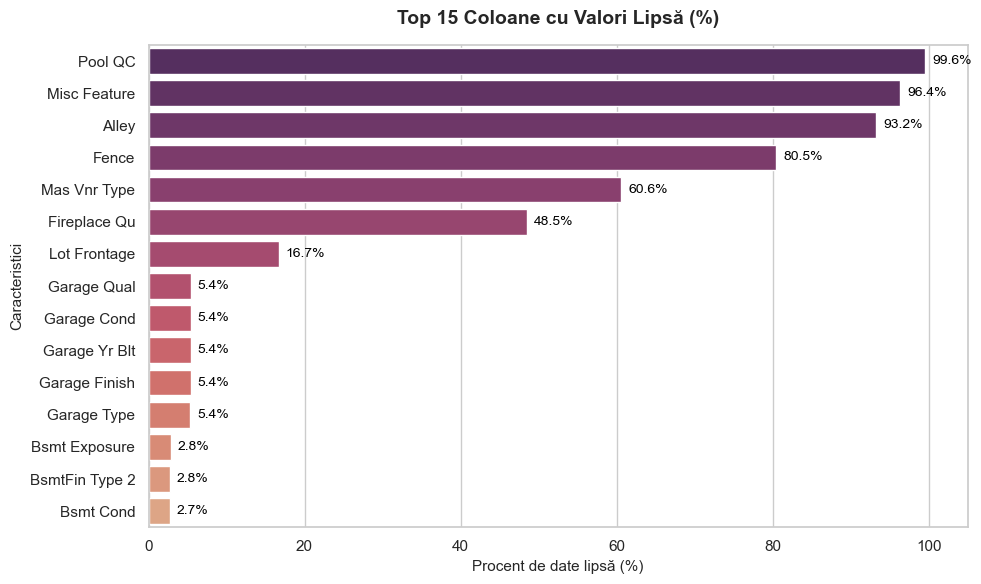

In [34]:
# top 15 coloane cu cele mai multe valori lipsă
top_missing = missing_df.head(15).reset_index()
top_missing.columns = ['Coloana', 'Valori Lipsa', 'Procent (%)']

plt.figure(figsize=(10, 6))
barplot = sns.barplot(
    data=top_missing,
    x='Procent (%)',
    y='Coloana',
    hue='Coloana',
    palette='flare_r',
    legend=False
)

# Etichete cu procent
for p in barplot.patches:
    width = p.get_width()
    if width > 0:
        barplot.annotate(
            f"{width:.1f}%",
            (width, p.get_y() + p.get_height() / 2.),
            ha='left', va='center',
            xytext=(5, 0), textcoords='offset points',
            fontsize=10, color='black'
        )

plt.title('Top 15 Coloane cu Valori Lipsă (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Procent de date lipsă (%)', fontsize=11)
plt.ylabel('Caracteristici', fontsize=11)
plt.xlim(0, 105) 
plt.tight_layout()
plt.show()

In [36]:
# 1. Outliers suprafața teren (Lot Area > 40,000 sq ft)
lot_area_outliers = df[df['Lot Area'] > 40000][['Order', 'Lot Area', 'Neighborhood', 'SalePrice']]
print(f"Număr proprietăți cu Lot Area > 40.000 sq ft: {len(lot_area_outliers)}")
display(lot_area_outliers)

# 2. Outliers: Gr Liv Area > 4000 sq ft
gr_liv_outliers = df[df['Gr Liv Area'] > 4000][['Order', 'Gr Liv Area', 'Overall Qual', 'SalePrice']]
print(f"Număr proprietăți cu Gr Liv Area > 4.000 sq ft: {len(gr_liv_outliers)}")
display(gr_liv_outliers)

Număr proprietăți cu Lot Area > 40.000 sq ft: 21


,Order,Lot Area,Neighborhood,SalePrice
15,16,53504,StoneBr,538000
314,315,57200,Timber,160000
504,505,46589,NoRidge,402000
956,957,215245,Timber,375000
1015,1016,47280,Gilbert,133000
1402,1403,53227,ClearCr,256000
1406,1407,45600,ClearCr,240000
1497,1498,47007,Edwards,284700
1498,1499,63887,Edwards,160000
1570,1571,164660,Timber,228950


Număr proprietăți cu Gr Liv Area > 4.000 sq ft: 5


,Order,Gr Liv Area,Overall Qual,SalePrice
1498,1499,5642,10,160000
1760,1761,4476,10,745000
1767,1768,4316,10,755000
2180,2181,5095,10,183850
2181,2182,4676,10,184750


# Interpretare Outliers
1. Suprafața terenului (`Lot Area > 40.000 sq ft`):
--> identificate 21 de proprietăți cu terenuri foarte mari, acestea reprezintă parcele extinse sau proprietăți semi-rurale care pot distorsiona modelele liniare dacă nu sunt tratate corespunzător
   
3. Anomaliile clasice (`Gr Liv Area > 4.000 sq ft`):
--> 5 proprietăți cu suprafață locuibilă extremă: înregistrările cu indicii 1498, 2180 și 2181 au calitatea maximă (`Overall Qual = 10`), dar prețuri nefiresc de mici (< $200.000). Conform autorului datasetului, acestea sunt vânzări atipice/parțiale și sunt recomandate pentru eliminare înainte de antrenarea modelelor.

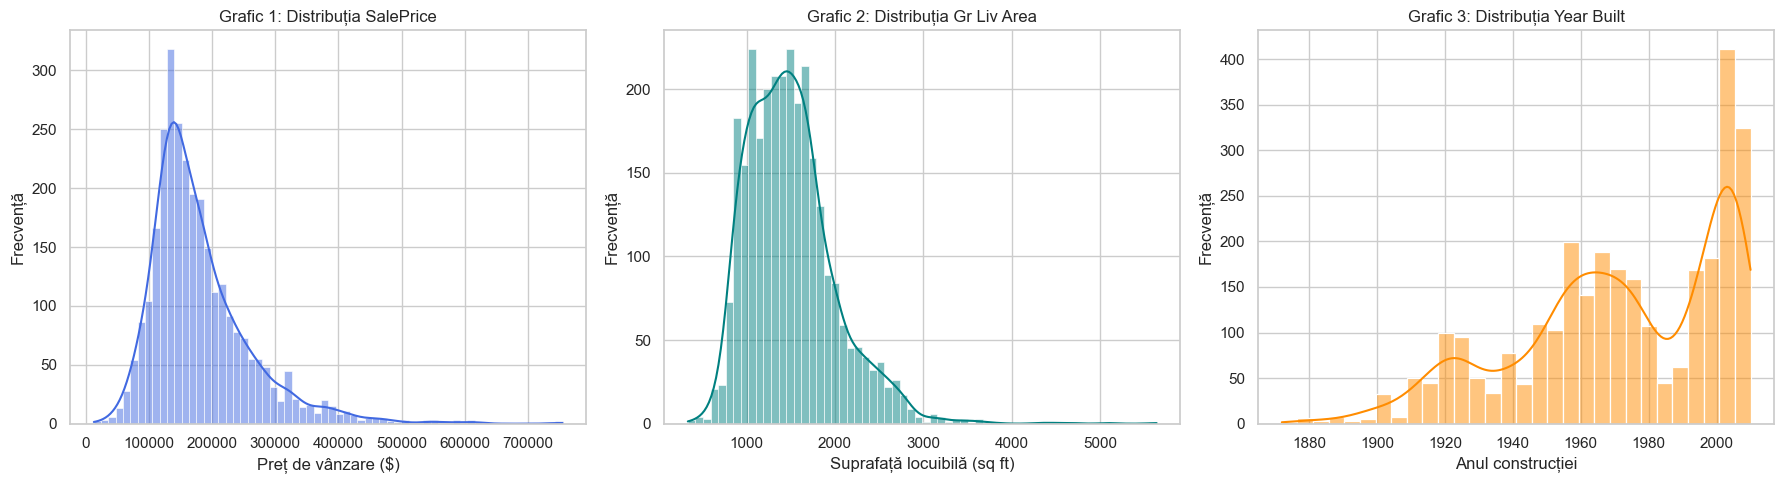

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafic 1: Distribuția prețului de vânzare
sns.histplot(df['SalePrice'], kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Grafic 1: Distribuția SalePrice')
axes[0].set_xlabel('Preț de vânzare ($)')
axes[0].set_ylabel('Frecvență')

# Grafic 2: Distribuția suprafeței locuibile (Gr Liv Area)
sns.histplot(df['Gr Liv Area'], kde=True, ax=axes[1], color='teal')
axes[1].set_title('Grafic 2: Distribuția Gr Liv Area')
axes[1].set_xlabel('Suprafață locuibilă (sq ft)')
axes[1].set_ylabel('Frecvență')

# Grafic 3: Distribuția anului de construcție (Year Built)
sns.histplot(df['Year Built'], kde=True, ax=axes[2], color='darkorange', bins=30)
axes[2].set_title('Grafic 3: Distribuția Year Built')
axes[2].set_xlabel('Anul construcției')
axes[2].set_ylabel('Frecvență')

plt.tight_layout()
plt.show()

### Interpretare Grafice 1–3 (Distribuții Univariate)
* **Grafic 1 (`SalePrice`):** Distribuția prețurilor de vânzare prezintă o asimetrie pronunțată spre dreapta (*right-skewed / positive skew*). Majoritatea locuințelor sunt în intervalul \$130.000 – \$210.000, existând o coadă de proprietăți care depășesc \$400.000
* **Grafic 2 (`Gr Liv Area`):** Suprafața locuibilă este tot asimetrică la dreapta, majoritatea caselor având între 1.000 și 1.800 sq ft. Se observă câteva exemple extreme dincolo de pragul de 4.000 sq ft identificate ca valori atipice
* **Grafic 3 (`Year Built`):** Anul construcției evidențiază o distribuție bimodală, reflectând etapele de dezvoltare imobiliară: primul vârf în perioada 1950–70 și al doilea vârf masiv de construcții noi până în 2000
    

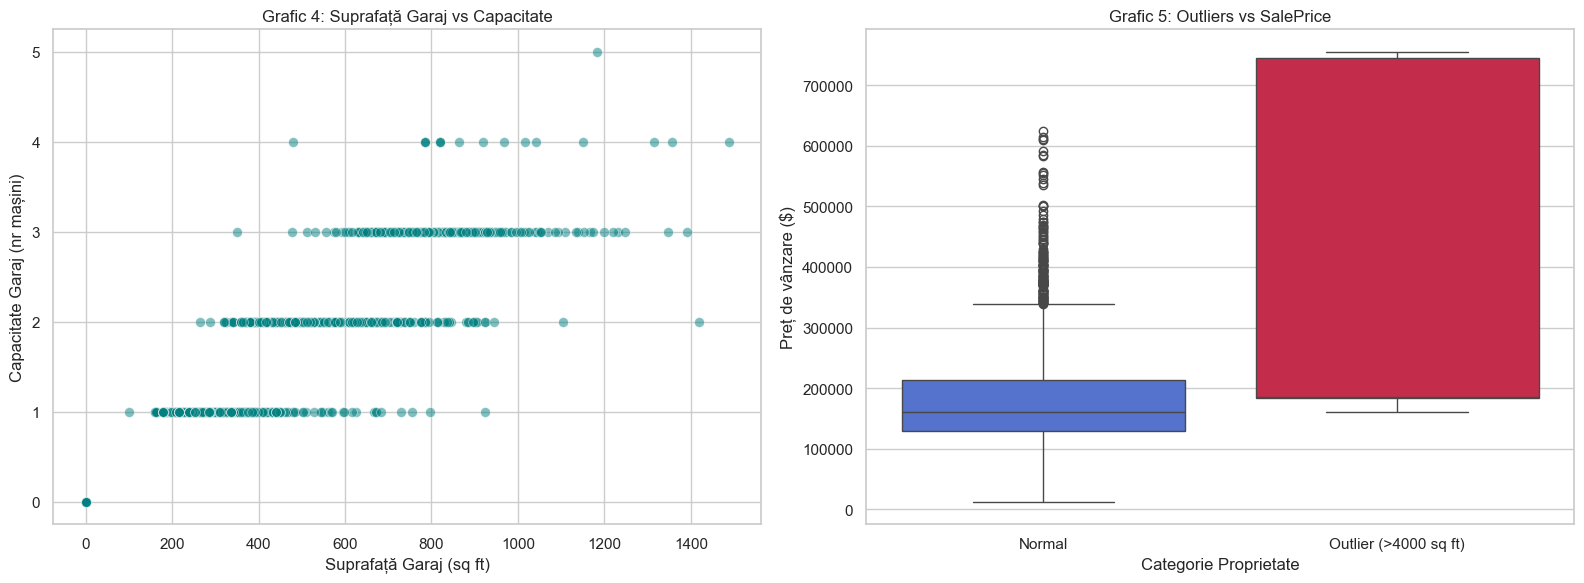

In [27]:
# Coloană temporară de etichetare a anomaliilor pentru Graficul 5
df['Is_Outlier'] = df['Gr Liv Area'].apply(lambda x: 'Outlier (>4000 sq ft)' if x > 4000 else 'Normal')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafic 4: Suprafață Garaj vs Capacitate 
sns.scatterplot(
    data=df,
    x='Garage Area',
    y='Garage Cars',
    alpha=0.5,
    color='teal',
    s=50,
    ax=axes[0]
)
axes[0].set_title('Grafic 4: Suprafață Garaj vs Capacitate')
axes[0].set_xlabel('Suprafață Garaj (sq ft)')
axes[0].set_ylabel('Capacitate Garaj (nr mașini)')

# Grafic 5: Outliers vs SalePrice 
sns.boxplot(
    data=df,
    x='Is_Outlier',
    y='SalePrice',
    hue='Is_Outlier',
    palette=['royalblue', 'crimson'],
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Grafic 5: Outliers vs SalePrice')
axes[1].set_xlabel('Categorie Proprietate')
axes[1].set_ylabel('Preț de vânzare ($)')

plt.tight_layout()
plt.show()

### Interpretare Grafice 4 și 5
* **Grafic 4 (Suprafață Garaj vs Capacitate - `Garage Area vs Garage Cars`):** Relația evidențiază o corelație liniară pozitivă puternică structurată pe niveluri distincte de capacitate (1, 2, 3 sau 4 mașini). Suprafața garajului crește proporțional cu capacitatea proiectată. Punctul din origine (0 sq ft, 0 locuri) identifică proprietățile fără garaj, iar dispersia pe orizontală pe fiecare palier reflectă diferențe de spațiu util (garaje standard vs. garaje cu atelier/depozitare adițională).
* **Grafic 5 (Outliers vs SalePrice):** Boxplot-ul compară prețurile locuințelor normale cu cele ale proprietăților atipice (`Gr Liv Area > 4000 sq ft`). Pentru categoria de outliers se observă o variabilitate extremă a prețurilor: deși toate au calitatea maximă a finisajelor (`Overall Qual = 10`), valorile sunt puternic polarizate între tranzacții reduse (< $200.000) și tranzacții de lux (> $700.000), confirmând anomaliile documentate

Bonus:

Ecuația dreptei: Garage Cars = 0.0031 * Garage Area + 0.2805


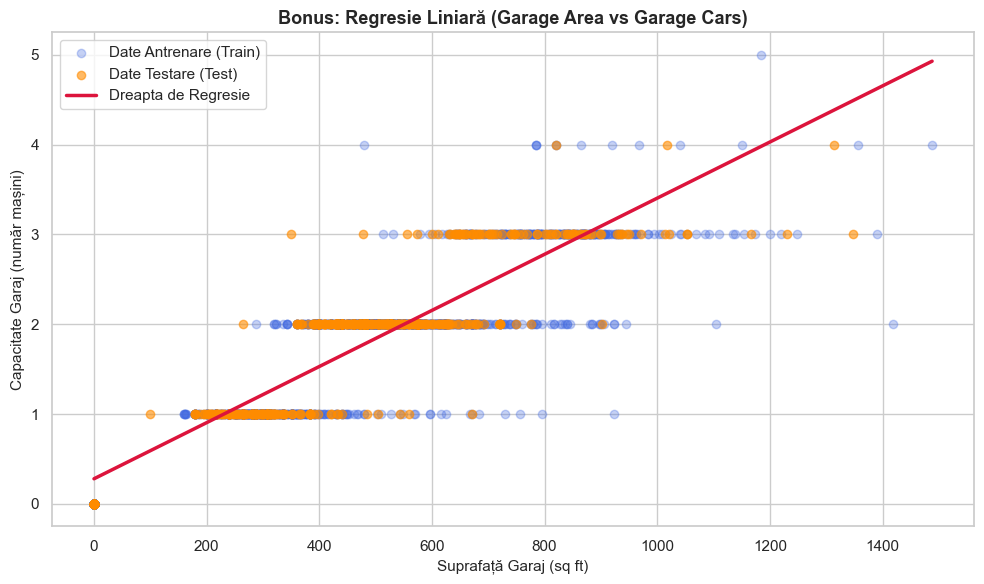

 Comparație Valori Reale vs. Prezise (Exemple din Setul de Test)


,Garage Area (sq ft),Capacitate Reală (mașini),Predicție Model (continuu),Predicție Rotunjită (întreg)
0,532.0,2.0,1.94,2
1,450.0,2.0,1.69,2
2,430.0,2.0,1.62,2
3,418.0,2.0,1.59,2
4,308.0,1.0,1.24,1
5,220.0,1.0,0.97,1


 Predicții pentru Dimensiuni Ipotetice


,Suprafață Ipotetică (sq ft),Capacitate Estimată,Capacitate Rotunjită
0,0,0.28,0
1,250,1.06,1
2,500,1.84,2
3,750,2.62,3
4,1000,3.40,3


In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import numpy as np

# 1. Pregătirea datelor
df_garage = df[['Garage Area', 'Garage Cars']].dropna().copy()

X = df_garage[['Garage Area']]
y = df_garage['Garage Cars']

# Împărțire train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Antrenare model
reg_garage = LinearRegression()
reg_garage.fit(X_train, y_train)

print(f"Ecuația dreptei: Garage Cars = {reg_garage.coef_[0]:.4f} * Garage Area + {reg_garage.intercept_:.4f}")

# 3. Grafic 
plt.figure(figsize=(10, 6))

plt.scatter(X_train['Garage Area'], y_train, color='royalblue', alpha=0.3, label='Date Antrenare (Train)')
plt.scatter(X_test['Garage Area'], y_test, color='darkorange', alpha=0.6, label='Date Testare (Test)')

# Trasare dreaptă de regresie ca DataFrame
x_vals = np.linspace(X['Garage Area'].min(), X['Garage Area'].max(), 100)
x_grid_df = pd.DataFrame({'Garage Area': x_vals})
y_grid_pred = reg_garage.predict(x_grid_df)

plt.plot(x_vals, y_grid_pred, color='crimson', linewidth=2.5, label='Dreapta de Regresie')

plt.title('Bonus: Regresie Liniară (Garage Area vs Garage Cars)', fontsize=13, fontweight='bold')
plt.xlabel('Suprafață Garaj (sq ft)', fontsize=11)
plt.ylabel('Capacitate Garaj (număr mașini)', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

# 4. Comparație Valori Reale vs. Prezise
y_test_pred = reg_garage.predict(X_test)
comparatie_df = pd.DataFrame({
    'Garage Area (sq ft)': X_test['Garage Area'].values[:6],
    'Capacitate Reală (mașini)': y_test.values[:6],
    'Predicție Model (continuu)': np.round(y_test_pred[:6], 2),
    'Predicție Rotunjită (întreg)': np.round(y_test_pred[:6]).astype(int)
})

print(" Comparație Valori Reale vs. Prezise (Exemple din Setul de Test)")
display(comparatie_df)

# Predicții - dimensiuni ipotetice
puncte_noi = pd.DataFrame({'Garage Area': [0, 250, 500, 750, 1000]})
pred_noi = reg_garage.predict(puncte_noi)
predictii_ipotetice = pd.DataFrame({
    'Suprafață Ipotetică (sq ft)': puncte_noi['Garage Area'],
    'Capacitate Estimată': np.round(pred_noi, 2),
    'Capacitate Rotunjită': np.round(pred_noi).astype(int)
})

print(" Predicții pentru Dimensiuni Ipotetice")
display(predictii_ipotetice)

### Interpretare Bonus: Relația dintre Garage Area și Garage Cars

* **De ce există această legătură:**
  Relația dintre suprafața garajului (`Garage Area`) și capacitatea acestuia (`Garage Cars`) este directă și cauzală, impusă de standardele de proiectare și spațiul fizic necesar parcării unui vehicul
* **Este o corelație aparentă / falsă (Spurious Correlation):**
  Nu este o corelație falsă; legătura are fundament fizic clar. Totuși, ambele caracteristici reflectă indirect dimensiunea generală a locuinței și segmentul de preț.
* **Comparație Valori Reale - Prezise:**
  Modelul oferă predicții continue logice care, prin rotunjire la cel mai apropiat număr întreg, reproduc capacitățile efective ale garajelor din setul de test și pentru cazurile ipotetice.
* **Limitările Modelului Liniar:**
  1. *Variabilă discretă modelată continuu:* Capacitatea este un număr întreg ($0, 1, 2, 3, 4$), iar regresia liniară estimează valori continue cu zecimale.
  2. *Variații de design:* Garajele de aceeași capacitate pot avea suprafețe diferite dacă includ spații suplimentare pentru depozitare sau atelier.